# DS201 · LAB 3: MẠNG NEURAL HỒI QUY (RNN, LSTM, GRU VÀ BiLSTM)

Họ tên: Mai Dương Hải Đăng
MSSV: 24520253

Bài làm Lab 3. Phần A–B làm theo hướng dẫn trên lớp, phần C chạy với cấu hình của đề (embedding 300, hidden 256, 5 lớp, 10 epoch).

In [1]:
# nếu thiếu thư viện thì bỏ dấu # rồi chạy
# %pip install -q --use-pep517 torch numpy pandas matplotlib scikit-learn seqeval

## Phần A. Chuẩn bị trước buổi học

### Kiểm tra môi trường và chọn cấu hình

Dùng lại vòng lặp PyTorch của Lab 1–2. `cfg` được đặt theo cấu hình chung của đề: embedding 300, hidden 256, 5 lớp, dropout 0.3, batch 32, Adam lr 1e-3, tối đa 10 epoch. Máy không có GPU nên toàn bộ notebook chạy trên CPU.

In [2]:
import copy, hashlib, json, random, time, urllib.request
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import (
    pad_sequence, pack_padded_sequence, pad_packed_sequence,
)
from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report, f1_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay,
)
from seqeval.metrics import f1_score as entity_f1
from seqeval.metrics import classification_report as entity_report
from seqeval.scheme import IOB2
import matplotlib.pyplot as plt

def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# cấu hình của đề: emb=300, hidden=256, layers=5, tối đa 10 epoch
cfg = dict(emb=300, hidden=256, layers=5, epochs=10, ner_epochs=10,
           batch=32, dropout=0.3, lr=1e-3)
base = Path.cwd()
LAB = base / "Lab3" if (base / "Lab3").is_dir() else base
DATA = LAB / "data"
ART = LAB / "checkpoints"
ART.mkdir(parents=True, exist_ok=True)
print("PyTorch:", torch.__version__, "| Thiết bị:", device)
print("Cấu hình:", cfg)

PyTorch: 2.15.0+cpu | Thiết bị: cpu
Cấu hình: {'emb': 300, 'hidden': 256, 'layers': 5, 'epochs': 10, 'ner_epochs': 10, 'batch': 32, 'dropout': 0.3, 'lr': 0.001}


### Tải dữ liệu và xác nhận đúng phiên bản

Mỗi người tải trực tiếp từ nguồn của bộ dữ liệu. Nếu đã tải trước giờ học, chương trình kiểm tra checksum rồi dùng lại tệp. Giữ thư mục data trên máy cá nhân; khi nộp GitHub chỉ ghi nguồn tải và cách chạy.

PhoNER cho phép sử dụng cho giáo dục/nghiên cứu và yêu cầu không phân phối lại dữ liệu. Tải từ kho VinAI; không đính kèm dữ liệu trong repo nộp bài.

In [3]:
# Tải một lần; không đọc nội dung test để chọn mô hình.
DATA_FILES = [('uit-vsfc/UIT-VSFC-train.json', 'https://drive.google.com/uc?export=download&id=1eJdEStCQBf3GtbOIQfIR2iS-Wb3nlfJX', 'e41e65672f2ade65ee8d2d394659a2bfeabbce987f0d2ad9e19998068a78fc1e'), ('uit-vsfc/UIT-VSFC-dev.json', 'https://drive.google.com/uc?export=download&id=1UWbzHFeUPu4AuofOEy0Fo0SFotVZHzUe', 'ab781a38209c17e640e077f83d82ecb9ea4f3469e63fc6ec2a232b0da6fbe823'), ('uit-vsfc/UIT-VSFC-test.json', 'https://drive.google.com/uc?export=download&id=1g4imdabNbswIu91K6zKFGalkjDBBqaQq', '14a6c5697907084086551a17c76e908dad88f2dc3b8be720c9880c8fc1212aa6'), ('phoner/train_syllable.json', 'https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/main/data/syllable/train_syllable.json', 'fb4097f6ac956a03e484319898db0dafc7283c135cd7888f803ad26a5a253419'), ('phoner/dev_syllable.json', 'https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/main/data/syllable/dev_syllable.json', 'c74393fb5d1547d51ddda175830892ca62a7efa2d93291b21a35cb21bfee612e'), ('phoner/test_syllable.json', 'https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/main/data/syllable/test_syllable.json', '4b677028d6db5e1dab74d727d88b719454da60cfeaba681d9ee401fc83b04c77')]
for rel, url, expected in DATA_FILES:
    path = DATA / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        with urllib.request.urlopen(url, timeout=90) as response:
            content = response.read()
        if hashlib.sha256(content).hexdigest() != expected:
            raise ValueError("Nguồn tải đã đổi hoặc trả về HTML: " + rel)
        path.write_bytes(content)
    actual = hashlib.sha256(path.read_bytes()).hexdigest()
    if actual != expected:
        raise ValueError("Checksum không khớp: " + rel)
print("Đã xác nhận 6/6 tệp dữ liệu bằng SHA-256.")

Đã xác nhận 6/6 tệp dữ liệu bằng SHA-256.


### Đọc JSON, JSON Lines và kiểm tra nhãn

UIT-VSFC có hai nhiệm vụ. Lab này chỉ dùng sentiment với ba nhãn negative, neutral, positive; topic không phải đầu vào. PhoNER bản syllable đã có token và nhãn tương ứng, vì vậy không tách từ lại.

In [4]:
LABELS = ["negative", "neutral", "positive"]
label_to_id = {name: i for i, name in enumerate(LABELS)}
vsfc, ner = {}, {}
for split in ["train", "dev", "test"]:
    path = DATA / "uit-vsfc" / f"UIT-VSFC-{split}.json"
    vsfc[split] = json.loads(path.read_text(encoding="utf-8-sig"))
    assert all(r["sentiment"] in LABELS for r in vsfc[split])
    path = DATA / "phoner" / f"{split}_syllable.json"
    ner[split] = [json.loads(line) for line in
                  path.read_text(encoding="utf-8-sig").splitlines()
                  if line.strip()]
    assert all(len(r["words"]) == len(r["tags"]) > 0
               for r in ner[split])
    print(split, "| UIT-VSFC:", len(vsfc[split]),
          "| PhoNER:", len(ner[split]))
counts = Counter(r["sentiment"] for r in vsfc["train"])
print("Sentiment train:", {k: counts[k] for k in LABELS})
print("Kiểm tra token/nhãn PhoNER: PASS")

train | UIT-VSFC: 11426 | PhoNER: 5027
dev | UIT-VSFC: 1583 | PhoNER: 2000
test | UIT-VSFC: 3166 | PhoNER: 3000
Sentiment train: {'negative': 5325, 'neutral': 458, 'positive': 5643}
Kiểm tra token/nhãn PhoNER: PASS


### Tự kiểm tra trước khi đến lớp

Đối chiếu số câu và tên nhãn với tài liệu. Phần test chỉ được kiểm tra cấu trúc ở bước chuẩn bị; lựa chọn mô hình và siêu tham số luôn dựa trên dev.

In [5]:
assert [len(vsfc[s]) for s in vsfc] == [11426, 1583, 3166]
assert [len(ner[s]) for s in ner] == [5027, 2000, 3000]
assert set(counts) == set(LABELS)
print("3/3 kiểm tra chuẩn bị: PASS")

3/3 kiểm tra chuẩn bị: PASS


## B.1. Từ trạng thái ẩn đến RNN nhiều lớp

### Tính trạng thái ẩn qua ba bước thời gian

Đề bài: tính h_t = tanh(0.5 x_t + 0.8 h_(t−1)) với x = [1, 1, 1] và h_0 = 0. Cùng một bộ trọng số được dùng lại ở mọi bước, nên độ dài chuỗi không quyết định số tham số.

In [6]:
h = torch.tensor(0.0)
for t, x_t in enumerate([1.0, 1.0, 1.0], start=1):
    h = torch.tanh(0.5 * x_t + 0.8 * h)
    print(f"h_{t} = {h.item():.6f}")
print(f"0.5**50 = {0.5**50:.3e}")

h_1 = 0.462117
h_2 = 0.701218
h_3 = 0.786037
0.5**50 = 8.882e-16


### Đối chiếu output, h_n và c_n

Với batch_first=True, đầu vào có shape [B, L, E]. output chứa trạng thái tại từng vị trí của lớp trên cùng; h_n chứa trạng thái cuối của từng lớp và từng chiều. LSTM còn trả về c_n, còn RNN và GRU chỉ trả về h_n.

In [7]:
seed_all()
toy = torch.randn(3, 5, 8)
for name, cls in [("RNN", nn.RNN), ("GRU", nn.GRU),
                  ("LSTM", nn.LSTM)]:
    layer = cls(8, 16, num_layers=2, batch_first=True)
    output, state = layer(toy)
    hidden = state[0] if name == "LSTM" else state
    print(name, "output:", tuple(output.shape),
          "h_n:", tuple(hidden.shape),
          "params:", sum(p.numel() for p in layer.parameters()))
bi = nn.LSTM(8, 16, num_layers=2,
             bidirectional=True, batch_first=True)
output, (h_n, c_n) = bi(toy)
print("BiLSTM:", tuple(output.shape), tuple(h_n.shape),
      tuple(c_n.shape))

RNN output: (3, 5, 16) h_n: (2, 3, 16) params: 960
GRU output: (3, 5, 16) h_n: (2, 3, 16) params: 2880
LSTM output: (3, 5, 16) h_n: (2, 3, 16) params: 3840
BiLSTM: (3, 5, 32) (4, 3, 16) (4, 3, 16)


## B.2. Từ văn bản đến batch embedding

### Xây từ điển từ tập train

Dùng phép tách theo khoảng trắng trên văn bản UIT-VSFC đã có trong tệp, giữ nguyên dấu gạch nối từ nếu có. Đây là quy ước đơn giản cho lab, không phải tuyên bố rằng mỗi âm tiết là một từ tiếng Việt. PhoNER giữ nguyên danh sách words, kể cả dấu câu và chữ hoa.

- TODO 1: Dùng từ điển; từ chưa thấy chuyển thành UNK.

In [8]:
PAD, UNK = 0, 1
def tokenize(text):
    return text.lower().split()

def build_vocab(sequences, min_freq=2):
    freq = Counter(t for tokens in sequences for t in tokens)
    tokens = sorted(t for t, n in freq.items() if n >= min_freq)
    return {"<pad>": PAD, "<unk>": UNK,
            **{t: i + 2 for i, t in enumerate(tokens)}}

vocab = build_vocab(tokenize(r["sentence"])
                    for r in vsfc["train"])
def encode(tokens, mapping):
    # Câu rỗng vẫn cần một bước để packing nhận length > 0.
    return [mapping.get(t, UNK) for t in tokens] or [UNK]

example = tokenize("giảng viên dạy rất hay")
print("Token minh họa:", example)
print("Chỉ số:", encode(example, vocab))
print("Kích thước từ điển train:", len(vocab))
assert vocab["<pad>"] == 0 and vocab["<unk>"] == 1

Token minh họa: ['giảng', 'viên', 'dạy', 'rất', 'hay']
Chỉ số: [394, 1313, 337, 978, 436]
Kích thước từ điển train: 1535


### Tạo batch có độ dài khác nhau

collate_fn trả về cả ids và lengths. Padding chỉ nhằm ghép các câu thành tensor, không phải nội dung của câu. Độ dài thật phải được giữ lại trước khi thêm padding.

In [9]:
def cls_rows(rows):
    return [(encode(tokenize(r["sentence"]), vocab),
             label_to_id[r["sentiment"]]) for r in rows]

def collate_cls(rows):
    ids = [torch.tensor(x, dtype=torch.long) for x, _ in rows]
    lengths = torch.tensor([len(x) for x in ids])
    x = pad_sequence(ids, batch_first=True, padding_value=PAD)
    y = torch.tensor([label for _, label in rows])
    return x, lengths, y

demo_rows = [(encode(tokenize(t), vocab), y) for t, y in [
    ("dạy hay", 2), ("nội dung còn khó hiểu", 0),
    ("bình thường", 1)]]
x, lengths, y = collate_cls(demo_rows)
print("ids shape:", tuple(x.shape), "| lengths:", lengths.tolist())
print("nhãn:", y.tolist())
emb = nn.Embedding(len(vocab), 8, padding_idx=PAD)
print("embedding shape:", tuple(emb(x).shape))
print("Vector PAD bằng 0:", bool(torch.all(emb.weight[PAD] == 0)))

ids shape: (3, 5) | lengths: [2, 5, 2]
nhãn: [2, 0, 1]
embedding shape: (3, 5, 8)
Vector PAD bằng 0: True


## B.3. Baseline và macro-F1 cho phân loại cảm xúc

### Chạy hai baseline trên UIT-VSFC

Đề bài: đo macro-F1 trên dev trước khi huấn luyện RNN. TF-IDF chỉ fit trên train; cả vectorizer và bộ phân loại đều không học từ dev/test. Nhãn neutral ít mẫu nên cần xem F1 từng lớp, thay vì chỉ nhìn accuracy.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

train_text = [r["sentence"] for r in vsfc["train"]]
dev_text = [r["sentence"] for r in vsfc["dev"]]
train_y = [label_to_id[r["sentiment"]] for r in vsfc["train"]]
dev_y = [label_to_id[r["sentiment"]] for r in vsfc["dev"]]
majority = Counter(train_y).most_common(1)[0][0]
baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                    token_pattern=r"(?u)\b\w+\b"),
    LogisticRegression(max_iter=1000, random_state=42),
)
t0 = time.perf_counter()
baseline.fit(train_text, train_y)
tfidf_fit_seconds = time.perf_counter() - t0
base_pred = baseline.predict(dev_text)
print("Majority dev macro-F1:", round(f1_score(
    dev_y, [majority] * len(dev_y), labels=[0, 1, 2],
    average="macro", zero_division=0), 4))
print("TF-IDF dev macro-F1:", round(f1_score(
    dev_y, base_pred, labels=[0, 1, 2],
    average="macro", zero_division=0), 4))
print(classification_report(dev_y, base_pred, labels=[0, 1, 2],
                            target_names=LABELS,
                            digits=4, zero_division=0))
tfidf_dev_f1 = f1_score(dev_y, base_pred, labels=[0, 1, 2],
                        average="macro", zero_division=0)
print("Thời gian fit TF-IDF + LR (giây):", round(tfidf_fit_seconds, 1))

Majority dev macro-F1: 0.2247
TF-IDF dev macro-F1: 0.6894
              precision    recall  f1-score   support

    negative     0.8855    0.9546    0.9188       705
     neutral     0.8182    0.1233    0.2143        73
    positive     0.9310    0.9391    0.9351       805

    accuracy                         0.9084      1583
   macro avg     0.8782    0.6723    0.6894      1583
weighted avg     0.9056    0.9084    0.8946      1583

Thời gian fit TF-IDF + LR (giây): 0.4


## B.4. LSTM: packing, huấn luyện và đánh giá

### Cài mô hình phân loại dùng packing

Embedding chuyển ids thành vector. pack_padded_sequence loại bước đệm khỏi phép hồi quy; lengths đặt trên CPU. Mô hình một chiều lấy h_n[-1]; mô hình hai chiều ghép h_n[-2] và h_n[-1]. Lớp cuối trả logits trực tiếp cho CrossEntropyLoss.

- TODO 2: Truyền độ dài thật cho packing.

In [11]:
class TextClassifier(nn.Module):
    def __init__(self, vocab_size, kind="LSTM", emb=64,
                 hidden=64, layers=1, dropout=0.3,
                 bidirectional=False):
        super().__init__()
        self.kind = kind
        self.bidirectional = bidirectional
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind]
        self.rnn = cls(emb, hidden, layers, batch_first=True,
                       bidirectional=bidirectional,
                       dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * (2 if bidirectional else 1), 3)

    def forward(self, ids, lengths):
        embedded = self.emb(ids)
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True,
            enforce_sorted=False,
        )
        _, state = self.rnn(packed)
        h = state[0] if self.kind == "LSTM" else state
        vec = torch.cat([h[-2], h[-1]], dim=1) \
              if self.bidirectional else h[-1]
        return self.fc(self.drop(vec))

model_args = {k: cfg[k] for k in
              ["emb", "hidden", "layers", "dropout"]}
seed_all()
lstm = TextClassifier(len(vocab), **model_args).to(device)
print("logits shape:", tuple(lstm(x.to(device), lengths).shape))
print("Số tham số:", sum(p.numel() for p in lstm.parameters()))

logits shape: (3, 3)
Số tham số: 3138007


### Kiểm tra cùng câu với hai độ dài đệm

Đề bài: đệm cùng một câu đến 8 và 64 vị trí rồi so logits trong eval mode. packing phải làm kết quả gần bằng nhau theo sai số số thực. padding_idx=0 chỉ ngăn học embedding PAD, bản thân nó không ngăn RNN cập nhật trạng thái ở các bước đệm.

In [12]:
sentence_ids = encode(tokenize("giảng viên dạy hay"), vocab)
def padded(length):
    return torch.tensor([sentence_ids +
                         [PAD] * (length - len(sentence_ids))],
                         device=device)

lens = torch.tensor([len(sentence_ids)])
lstm.eval()
with torch.no_grad():
    a = lstm(padded(8), lens)
    b = lstm(padded(64), lens)
    raw_a, _ = lstm.rnn(lstm.emb(padded(8)))
    raw_b, _ = lstm.rnn(lstm.emb(padded(64)))
torch.testing.assert_close(a, b, atol=1e-6, rtol=1e-5)
print("Packing, đệm 8 và 64: PASS")
print("Sai khác khi dùng output[:, -1] không packing:",
      round((raw_a[:, -1] - raw_b[:, -1]).abs().max().item(), 6))

Packing, đệm 8 và 64: PASS
Sai khác khi dùng output[:, -1] không packing: 0.002775


### Chuẩn bị DataLoader

Dùng toàn bộ train và dev; từ điển chỉ xây từ train. Mọi mô hình phân loại dùng cùng dữ liệu và cùng thứ tự batch khởi tạo từ seed 42.

In [13]:
cls_train = cls_rows(vsfc["train"])
cls_dev = cls_rows(vsfc["dev"])
def cls_loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg["batch"],
                      shuffle=shuffle, collate_fn=collate_cls,
                      generator=torch.Generator().manual_seed(42))

dev_loader = cls_loader(cls_dev)
print("Số câu train/dev:",
      len(cls_train), len(cls_dev))

Số câu train/dev: 11426 1583


### Viết vòng lặp huấn luyện và chọn checkpoint

Mỗi batch: zero_grad → forward → loss → backward → clip gradient → step. Loss mỗi epoch được lấy trung bình có trọng số theo số mẫu. eval kết hợp no_grad để đánh giá; chỉ trạng thái có macro-F1 tốt nhất trên dev được giữ lại.

- TODO 3: Chặn chuẩn gradient sau backward, trước step.

In [14]:
def evaluate_cls(model, loader):
    model.eval()
    true, pred = [], []
    with torch.no_grad():
        for ids, lengths, labels in loader:
            logits = model(ids.to(device), lengths)
            true.extend(labels.tolist())
            pred.extend(logits.argmax(-1).cpu().tolist())
    score = f1_score(true, pred, labels=[0, 1, 2],
                     average="macro", zero_division=0)
    return score, true, pred

def fit_cls(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    criterion = nn.CrossEntropyLoss()
    best, best_state, history = -1.0, None, []
    loader = cls_loader(cls_train, shuffle=True)
    for epoch in range(1, cfg["epochs"] + 1):
        start = time.perf_counter()
        model.train()
        total_loss, total = 0.0, 0
        for ids, lengths, labels in loader:
            ids, labels = ids.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(ids, lengths), labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * labels.numel()
            total += labels.numel()
        seconds = time.perf_counter() - start
        score, _, _ = evaluate_cls(model, dev_loader)
        history.append(dict(epoch=epoch, loss=total_loss / total,
                            dev_f1=score, seconds=seconds))
        if score > best:
            best, best_state = score, copy.deepcopy(model.state_dict())
        print(f"{name} epoch {epoch}: loss={total_loss/total:.4f} "
              f"dev_macro_F1={score:.4f}")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART / f"{name}.pt")
    return history
print("Đã định nghĩa fit_cls và evaluate_cls.")

Đã định nghĩa fit_cls và evaluate_cls.


### Huấn luyện LSTM và đọc F1 từng lớp

Đây là mô hình của Bài 1: LSTM 5 lớp, hidden 256. Checkpoint được chọn theo macro-F1 dev, report bên dưới là của checkpoint đó trên dev. Baseline ở B.3 dùng cùng train/dev nên có thể đặt cạnh nhau.

In [15]:
seed_all()
lstm = TextClassifier(len(vocab), kind="LSTM", **model_args).to(device)
lstm_history = fit_cls(lstm, "lstm")
lstm_score, y_true, y_pred = evaluate_cls(lstm, dev_loader)
print(classification_report(y_true, y_pred, labels=[0, 1, 2],
                            target_names=LABELS,
                            digits=4, zero_division=0))

lstm epoch 1: loss=0.4227 dev_macro_F1=0.6061


lstm epoch 2: loss=0.2809 dev_macro_F1=0.7375


lstm epoch 3: loss=0.2460 dev_macro_F1=0.7640


lstm epoch 4: loss=0.2078 dev_macro_F1=0.7758


lstm epoch 5: loss=0.1782 dev_macro_F1=0.8062


lstm epoch 6: loss=0.1510 dev_macro_F1=0.8100


lstm epoch 7: loss=0.1325 dev_macro_F1=0.7751


lstm epoch 8: loss=0.1048 dev_macro_F1=0.7878


lstm epoch 9: loss=0.0915 dev_macro_F1=0.7687


lstm epoch 10: loss=0.0798 dev_macro_F1=0.7767


              precision    recall  f1-score   support

    negative     0.9340    0.9433    0.9386       705
     neutral     0.6875    0.4521    0.5455        73
    positive     0.9356    0.9565    0.9459       805

    accuracy                         0.9274      1583
   macro avg     0.8524    0.7839    0.8100      1583
weighted avg     0.9234    0.9274    0.9242      1583



## B.5. GRU và so sánh có kiểm soát

### Huấn luyện GRU với cùng cấu hình

GRU trả thẳng h_n, còn LSTM trả (h_n, c_n). Giữ nguyên cách chia dữ liệu, embedding, hidden size, số lớp, batch và learning rate. Số tham số và thời gian là hai yếu tố cần đọc cùng chất lượng phân loại.

In [16]:
seed_all()
gru = TextClassifier(len(vocab), kind="GRU", **model_args).to(device)
gru_history = fit_cls(gru, "gru")
gru_score, _, _ = evaluate_cls(gru, dev_loader)
comparison = pd.DataFrame([
    {"model": name, "dev_macro_F1": score,
     "parameters": sum(p.numel() for p in model.parameters()),
     "seconds_per_epoch": np.mean([r["seconds"] for r in history])}
    for name, model, score, history in [
        ("LSTM", lstm, lstm_score, lstm_history),
        ("GRU", gru, gru_score, gru_history)]
])
comparison.to_csv(ART / "classification_dev.csv", index=False)
print(comparison.drop(columns="seconds_per_epoch").to_string(index=False))
print("Đã lưu thời gian/epoch trong classification_dev.csv.")

gru epoch 1: loss=0.3886 dev_macro_F1=0.6981


gru epoch 2: loss=0.2648 dev_macro_F1=0.7254


gru epoch 3: loss=0.2230 dev_macro_F1=0.7978


gru epoch 4: loss=0.1906 dev_macro_F1=0.7674


gru epoch 5: loss=0.1623 dev_macro_F1=0.7988


gru epoch 6: loss=0.1306 dev_macro_F1=0.7851


gru epoch 7: loss=0.1113 dev_macro_F1=0.8049


gru epoch 8: loss=0.0940 dev_macro_F1=0.7820


gru epoch 9: loss=0.0763 dev_macro_F1=0.8044


gru epoch 10: loss=0.0662 dev_macro_F1=0.7942


model  dev_macro_F1  parameters
 LSTM      0.810001     3138007
  GRU      0.804856     2468823
Đã lưu thời gian/epoch trong classification_dev.csv.


### Vẽ đường học và ma trận nhầm lẫn

Loss train và macro-F1 dev theo epoch của LSTM và GRU, cùng confusion matrix trên dev của checkpoint tốt nhất. Chủ yếu xem lớp neutral bị nhầm sang lớp nào.

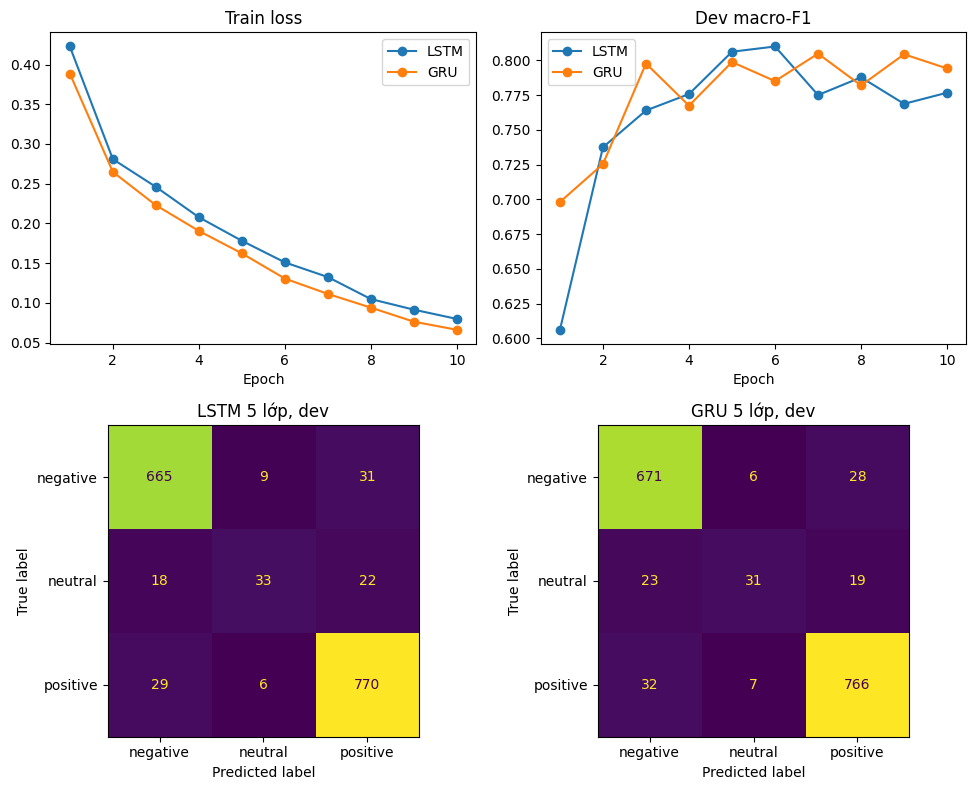

Đã lưu classification.png.


In [17]:
_, true_g, pred_g = evaluate_cls(gru, dev_loader)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for name, history in [("LSTM", lstm_history), ("GRU", gru_history)]:
    axes[0, 0].plot([r["epoch"] for r in history],
                    [r["loss"] for r in history], marker="o", label=name)
    axes[0, 1].plot([r["epoch"] for r in history],
                    [r["dev_f1"] for r in history], marker="o", label=name)
axes[0, 0].set_title("Train loss")
axes[0, 1].set_title("Dev macro-F1")
for ax in axes[0]:
    ax.set_xlabel("Epoch")
    ax.legend()
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=[0, 1, 2], display_labels=LABELS,
    ax=axes[1, 0], colorbar=False)
axes[1, 0].set_title("LSTM 5 lớp, dev")
ConfusionMatrixDisplay.from_predictions(
    true_g, pred_g, labels=[0, 1, 2], display_labels=LABELS,
    ax=axes[1, 1], colorbar=False)
axes[1, 1].set_title("GRU 5 lớp, dev")
fig.tight_layout()
fig.savefig(ART / "classification.png", dpi=150)
plt.show()
print("Đã lưu classification.png.")

### Các câu dự đoán sai trên dev

Chỉ xem dev. In 8 câu sai đầu tiên của LSTM kèm dự đoán của GRU, và đếm các cặp nhãn thật → nhãn dự đoán.

In [18]:
dev_sent = [r["sentence"] for r in vsfc["dev"]]
wrong = [i for i, (t, p) in enumerate(zip(y_true, y_pred)) if t != p]
print(f"LSTM sai {len(wrong)}/{len(y_true)} câu dev")
for i in wrong[:8]:
    print(f"- thật={LABELS[y_true[i]]} | LSTM={LABELS[y_pred[i]]} "
          f"| GRU={LABELS[pred_g[i]]}")
    print("  ", dev_sent[i])

pairs = Counter((LABELS[t], LABELS[p]) for t, p in zip(y_true, y_pred) if t != p)
print("\nLSTM, các cặp (thật → dự đoán) bị nhầm nhiều nhất:")
for (t, p), n in pairs.most_common():
    print(f"  {t} → {p}: {n}")

LSTM sai 115/1583 câu dev
- thật=neutral | LSTM=negative | GRU=negative
   em không có bất cứ một lời phê bình nào .
- thật=negative | LSTM=positive | GRU=negative
   đôi khi giảng dạy quá nhiệt tình mà quên mất cả thời gian ( hết giờ học giảng viên vẫn dạy thêm 10 - 15 phút ) .
- thật=negative | LSTM=positive | GRU=positive
   ôn tập kỹ trước khi thi hoặc trong lúc giảng dạy cập nhật đến những vấn đề có thể cho ra trong bài thi .
- thật=neutral | LSTM=positive | GRU=positive
   thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề .
- thật=negative | LSTM=positive | GRU=negative
   cô rất nghiêm .
- thật=positive | LSTM=neutral | GRU=neutral
   đề cập về tính thực tế , liên quan của hệ thống kiến thức .
- thật=positive | LSTM=negative | GRU=negative
   ngoài ra cung cấp một vài thông tin bổ sung về việc học công nghệ thông tin hiệu quả hơn .
- thật=positive | LSTM=negative | GRU=negative
   thúc đẩy sinh viên tự học đạt điểm cao trong các kỳ thi .

LSTM, các cặp (thật → dự đ

### Nhận xét lỗi

LSTM sai 115/1583 câu dev, GRU cũng sai 115 câu. Cặp nhầm nhiều nhất là negative ↔ positive (31 và 29), sau đó là neutral bị đoán thành positive hoặc negative (22 và 18). Neutral chỉ có 73 câu dev nên mô hình học lớp này kém nhất.

Một số câu đáng chú ý:
- "em không có bất cứ một lời phê bình nào ." (thật: neutral, cả hai đoán negative). Câu này không chê gì cả nhưng có "không" và "phê bình". Có thể mô hình bắt từ khóa chứ chưa hiểu phủ định.
- "đôi khi giảng dạy quá nhiệt tình mà quên mất cả thời gian ( ... )" (thật: negative, LSTM đoán positive). Câu có từ "nhiệt tình" nghiêng về khen, nhưng ý cả câu là phàn nàn dạy lố giờ.
- "cô rất nghiêm ." (thật: negative, LSTM đoán positive, GRU đoán negative). Câu ngắn, từ "nghiêm" có thể khen hoặc chê tùy ngữ cảnh, hai mô hình trả lời khác nhau.
- "ngoài ra cung cấp một vài thông tin bổ sung về việc học công nghệ thông tin hiệu quả hơn ." (thật: positive, cả hai đoán negative). Câu mang tính đề xuất, không có từ cảm xúc rõ. Nhãn trong trường hợp này cũng khá chủ quan.

Nhìn chung lỗi tập trung ở câu ngắn, câu phủ định và câu đề xuất. Chưa thử cách nào để sửa các lỗi này.

## B.6. BiLSTM và nhận diện thực thể PhoNER

### Phân biệt F1 theo token và theo thực thể

Ví dụ này do người soạn tạo: token Hà Nội có nhãn B-LOCATION, I-LOCATION. Dự đoán chỉ đúng chữ Hà vẫn sai thực thể vì thiếu biên kết thúc. Lab dùng seqeval ở chế độ strict IOB2, tính micro-F1 trên các thực thể; không dùng macro-F1 của bài phân loại câu cho NER.

In [19]:
gold = [["O", "B-LOCATION", "I-LOCATION", "O"]]
guess = [["O", "B-LOCATION", "O", "O"]]
token_accuracy = np.mean(np.array(gold[0]) == np.array(guess[0]))
print("Token accuracy:", token_accuracy)
print("Entity F1:", entity_f1(gold, guess, mode="strict", scheme=IOB2))
print("Ví dụ tự tạo: đúng 3/4 token nhưng đúng 0/1 thực thể.")

Token accuracy: 0.75
Entity F1: 0.0
Ví dụ tự tạo: đúng 3/4 token nhưng đúng 0/1 thực thể.


### Mã hóa PhoNER và bỏ qua nhãn đệm

Xây từ điển và danh sách nhãn từ train PhoNER. PAD_TAG=-100 chỉ dùng để đệm nhãn, không phải lớp dự đoán thứ 22. Không cắt câu trong lab này nhằm giữ trọn biên thực thể; padding động theo câu dài nhất của batch.

In [20]:
ner_vocab = build_vocab(r["words"] for r in ner["train"])
TAGS = sorted({tag for row in ner["train"] for tag in row["tags"]})
tag_to_id = {tag: i for i, tag in enumerate(TAGS)}
PAD_TAG = -100
assert len(TAGS) == 21
assert all(tag in tag_to_id for split in ["dev", "test"]
           for row in ner[split] for tag in row["tags"])

def ner_rows(rows):
    return [(encode(r["words"], ner_vocab),
             [tag_to_id[t] for t in r["tags"]]) for r in rows]

def collate_ner(rows):
    ids = [torch.tensor(x) for x, _ in rows]
    tags = [torch.tensor(y) for _, y in rows]
    lengths = torch.tensor([len(x) for x in ids])
    return (pad_sequence(ids, batch_first=True, padding_value=PAD),
            lengths,
            pad_sequence(tags, batch_first=True,
                         padding_value=PAD_TAG))

ner_train = ner_rows(ner["train"])
ner_dev = ner_rows(ner["dev"])
def ner_loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg["batch"],
                      shuffle=shuffle, collate_fn=collate_ner,
                      generator=torch.Generator().manual_seed(42))

nx, nl, ny = next(iter(ner_loader(ner_train)))
print("Số nhãn BIO:", len(TAGS), "| PAD_TAG:", PAD_TAG)
print("ids/nhãn:", tuple(nx.shape), tuple(ny.shape))
print("Số câu train/dev:", len(ner_train), len(ner_dev))

Số nhãn BIO: 21 | PAD_TAG: -100
ids/nhãn: (32, 117) (32, 117)
Số câu train/dev: 5027 2000


### Cài BiLSTM cho từng token

BiLSTM trả vector 2H tại từng vị trí. pad_packed_sequence khôi phục chiều dài bằng total_length để logits và nhãn đệm luôn cùng shape. Linear(2H, 21) phân loại mỗi token độc lập; đây là BiLSTM thuần, chưa có CRF.

- TODO 4: Ghép hai chiều nên đầu vào Linear có 2H chiều.
- TODO 5: Bỏ qua đúng nhãn đệm -100 khi tính loss.

In [21]:
class TokenTagger(nn.Module):
    def __init__(self, vocab_size, num_tags, emb=64,
                 hidden=64, layers=1, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.rnn = nn.LSTM(
            emb, hidden, layers, batch_first=True,
            bidirectional=True,
            dropout=dropout if layers > 1 else 0.0,
        )
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * 2, num_tags)

    def forward(self, ids, lengths):
        packed = pack_padded_sequence(
            self.emb(ids), lengths.cpu(), batch_first=True,
            enforce_sorted=False,
        )
        output, _ = self.rnn(packed)
        output, _ = pad_packed_sequence(
            output, batch_first=True, total_length=ids.size(1),
        )
        return self.fc(self.drop(output))

seed_all()
tagger = TokenTagger(len(ner_vocab), len(TAGS), **model_args).to(device)
criterion_ner = nn.CrossEntropyLoss(ignore_index=PAD_TAG)
logits = tagger(nx.to(device), nl)
loss = criterion_ner(logits.reshape(-1, len(TAGS)),
                     ny.to(device).reshape(-1))
assert logits.shape[:2] == ny.shape
print("logits:", tuple(logits.shape), "| Loss hữu hạn:",
      bool(torch.isfinite(loss)))

logits: (32, 117, 21) | Loss hữu hạn: True


### Kiểm tra padding của BiLSTM và loss

Kiểm tra cả hai chiều hồi quy: cùng token thật với đệm 8/64 phải cho cùng logits. Thêm nhãn -100 cũng không được làm đổi cross-entropy trung bình. Dùng eval để tắt dropout trước khi đối chiếu.

In [22]:
toy_ids = encode(["Ví", "dụ", "tự", "tạo"], ner_vocab)
def padded_ner(n):
    return torch.tensor([toy_ids + [PAD] * (n - len(toy_ids))],
                         device=device)

tagger.eval()
with torch.no_grad():
    n8 = tagger(padded_ner(8), torch.tensor([4]))
    n64 = tagger(padded_ner(64), torch.tensor([4]))
torch.testing.assert_close(n8[:, :4], n64[:, :4],
                           atol=1e-6, rtol=1e-5)
target = torch.tensor([[tag_to_id["O"]] * 4], device=device)
a = criterion_ner(n8[:, :4].reshape(-1, len(TAGS)), target.flatten())
padded_target = torch.cat([
    target, torch.full((1, 4), PAD_TAG, device=device)], dim=1)
b = criterion_ner(n8.reshape(-1, len(TAGS)), padded_target.flatten())
torch.testing.assert_close(a, b)
print("BiLSTM đệm 8/64: PASS | Loss bỏ padding: PASS")

BiLSTM đệm 8/64: PASS | Loss bỏ padding: PASS


### Huấn luyện và đánh giá BiLSTM bằng seqeval

Đây là mô hình của Bài 3. Dự đoán và nhãn thật được cắt theo độ dài thật trước khi đổi sang nhãn chuỗi, nên PAD không được tính vào F1. Checkpoint chọn theo entity-F1 dev.

- TODO 6: Cắt nhãn thật theo độ dài, bỏ PAD_TAG trước khi đổi nhãn.
- TODO 7: Chỉ chấm dự đoán tại token thật.

In [23]:
def evaluate_ner(model, loader):
    model.eval()
    true, pred = [], []
    with torch.no_grad():
        for ids, lengths, labels in loader:
            predicted = model(ids.to(device), lengths).argmax(-1).cpu()
            for actual, guessed, length in zip(labels, predicted, lengths):
                n = int(length)
                true.append([TAGS[int(i)] for i in actual[:n]])
                pred.append([TAGS[int(i)] for i in guessed[:n]])
    score = entity_f1(true, pred, mode="strict", scheme=IOB2,
                      zero_division=0)
    return score, true, pred

def fit_ner(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    best, best_state, history = -1.0, None, []
    train_loader = ner_loader(ner_train, shuffle=True)
    for epoch in range(1, cfg["ner_epochs"] + 1):
        model.train()
        start = time.perf_counter()
        total_loss, tokens = 0.0, 0
        for ids, lengths, labels in train_loader:
            ids, labels = ids.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(ids, lengths)
            loss = criterion_ner(logits.reshape(-1, len(TAGS)),
                                 labels.reshape(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            count = int((labels != PAD_TAG).sum())
            total_loss += loss.item() * count
            tokens += count
        seconds = time.perf_counter() - start
        score, _, _ = evaluate_ner(model, ner_loader(ner_dev))
        history.append(dict(epoch=epoch, loss=total_loss/tokens,
                            dev_f1=score, seconds=seconds))
        if score > best:
            best, best_state = score, copy.deepcopy(model.state_dict())
        print(f"BiLSTM epoch {epoch}: loss={total_loss/tokens:.4f} "
              f"dev_entity_F1={score:.4f}")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, ART / "bilstm_ner.pt")
    return history

ner_history = fit_ner(tagger)
ner_score, ner_true, ner_pred = evaluate_ner(tagger, ner_loader(ner_dev))
print(entity_report(ner_true, ner_pred, mode="strict", scheme=IOB2,
                     digits=4, zero_division=0))

BiLSTM epoch 1: loss=0.6949 dev_entity_F1=0.6676


BiLSTM epoch 2: loss=0.1710 dev_entity_F1=0.8240


BiLSTM epoch 3: loss=0.0919 dev_entity_F1=0.8657


BiLSTM epoch 4: loss=0.0657 dev_entity_F1=0.8773


BiLSTM epoch 5: loss=0.0483 dev_entity_F1=0.8883


BiLSTM epoch 6: loss=0.0394 dev_entity_F1=0.8963


BiLSTM epoch 7: loss=0.0313 dev_entity_F1=0.8903


BiLSTM epoch 8: loss=0.0317 dev_entity_F1=0.8945


BiLSTM epoch 9: loss=0.0226 dev_entity_F1=0.9002


BiLSTM epoch 10: loss=0.0189 dev_entity_F1=0.9074


                     precision    recall  f1-score   support

                AGE     0.9475    0.9501    0.9488       361
               DATE     0.9689    0.9619    0.9654      1103
             GENDER     0.9760    0.8809    0.9260       277
                JOB     0.7742    0.5455    0.6400       132
           LOCATION     0.9240    0.9149    0.9194      2737
               NAME     0.7263    0.6915    0.7084       188
       ORGANIZATION     0.8876    0.8022    0.8427       551
         PATIENT_ID     0.9439    0.9624    0.9530      1276
SYMPTOM_AND_DISEASE     0.8292    0.7924    0.8104       766
     TRANSPORTATION     0.8602    0.9195    0.8889        87

          micro avg     0.9177    0.8974    0.9074      7478
          macro avg     0.8838    0.8421    0.8603      7478
       weighted avg     0.9163    0.8974    0.9062      7478



### Các kiểu lỗi NER trên dev

Mỗi thực thể thật trên dev được xếp vào một nhóm: đúng, sai loại (đúng biên), sai biên (đúng loại), sai cả hai, hoặc bỏ sót. Thực thể mô hình đoán mà không chạm thực thể thật nào là dự đoán thừa. Phần này dùng `get_entities` của seqeval, chỉ để phân tích; điểm F1 chính vẫn lấy từ chế độ strict IOB2 ở ô trên.

In [24]:
from seqeval.metrics.sequence_labeling import get_entities

def ner_error_types(true_seqs, pred_seqs):
    counts = Counter()
    for t, p in zip(true_seqs, pred_seqs):
        gold, guess = get_entities(t), get_entities(p)
        guess_set = set(guess)
        for ent in gold:
            typ, s, e = ent
            if ent in guess_set:
                counts["đúng"] += 1
                continue
            over = [x for x in guess if x[1] <= e and s <= x[2]]
            if not over:
                counts["bỏ sót"] += 1
            elif any((x[1], x[2]) == (s, e) for x in over):
                counts["sai loại"] += 1
            elif any(x[0] == typ for x in over):
                counts["sai biên"] += 1
            else:
                counts["sai cả biên và loại"] += 1
        for x in guess:
            if not any(x[1] <= g[2] and g[1] <= x[2] for g in gold):
                counts["dự đoán thừa"] += 1
    return counts

err = ner_error_types(ner_true, ner_pred)
n_gold = sum(len(get_entities(t)) for t in ner_true)
print("Số thực thể thật trên dev:", n_gold)
gold_keys = ["đúng", "sai loại", "sai biên", "sai cả biên và loại", "bỏ sót"]
assert sum(err[k] for k in gold_keys) == n_gold
for k in gold_keys + ["dự đoán thừa"]:
    print(f"  {k:<22}{err[k]:>6}")

# loại thực thể bị bỏ sót hoặc nhầm nhiều nhất
miss = Counter()
for t, p in zip(ner_true, ner_pred):
    guess_set = set(get_entities(p))
    for ent in get_entities(t):
        if ent not in guess_set:
            miss[ent[0]] += 1
print("\nThực thể thật không khớp hẳn, theo loại:", dict(miss.most_common()))

Số thực thể thật trên dev: 7478
  đúng                    6726
  sai loại                 113
  sai biên                 318
  sai cả biên và loại       26
  bỏ sót                   295
  dự đoán thừa             225



Thực thể thật không khớp hẳn, theo loại: {'LOCATION': 227, 'SYMPTOM_AND_DISEASE': 153, 'ORGANIZATION': 108, 'JOB': 60, 'NAME': 56, 'PATIENT_ID': 48, 'DATE': 42, 'GENDER': 33, 'AGE': 18, 'TRANSPORTATION': 7}


### Nhận xét lỗi NER

Trên dev có 7478 thực thể thật, mô hình đoán đúng 6726 (chấm theo cách phân nhóm ở trên). Các kiểu lỗi còn lại:
- Sai biên (đúng loại nhưng sai ranh giới): 318, là kiểu lỗi nhiều nhất.
- Bỏ sót: 295.
- Dự đoán thừa: 225 thực thể mô hình đoán mà không chạm thực thể thật nào.
- Sai loại (đúng ranh giới): 113.
- Sai cả biên và loại: 26.

Theo loại thực thể, LOCATION có nhiều thực thể không khớp nhất (227) vì chiếm số lượng lớn (2737). Nhưng các loại ít mẫu mới kém nhất theo F1: JOB (132 mẫu, F1 dev 0.64) và NAME (188 mẫu, F1 dev 0.71). Trên test JOB còn 0.49, recall chỉ 0.40.

Ví dụ tự tạo để minh họa từng kiểu lỗi (không lấy từ dữ liệu): trong câu "Bệnh nhân làm ở công ty ABC tại Hà Nội", nếu mô hình chỉ gán "ABC" mà thiếu "công ty" thì là sai biên; nếu gán "Hà Nội" là ORGANIZATION thì là sai loại; nếu không gán gì cho "Hà Nội" thì là bỏ sót. Đây chỉ là minh họa, chưa đọc từng câu dev để xác nhận nguyên nhân thật của từng lỗi.

## Bài 4*. Độ sâu của LSTM

Chọn hướng (a): LSTM với 1, 2, 5 lớp, hidden 256, giữ nguyên dữ liệu, seed, optimizer và cách chọn checkpoint. Bản 5 lớp là mô hình của Bài 1. Chỉ so sánh trên dev ở bước này, test được chấm một lần ở cuối cùng với mọi mô hình.

In [25]:
def n_params(model):
    return sum(p.numel() for p in model.parameters())

def run_info(name, model, history):
    best = max(history, key=lambda r: r["dev_f1"])
    return dict(model=name, dev_macro_F1=best["dev_f1"],
                best_epoch=best["epoch"], parameters=n_params(model),
                seconds_per_epoch=float(np.mean([r["seconds"] for r in history])))

depth_models, depth_histories = {5: lstm}, {5: lstm_history}
for n_layers in [1, 2]:
    seed_all()
    m = TextClassifier(len(vocab), kind="LSTM",
                       **dict(model_args, layers=n_layers)).to(device)
    depth_histories[n_layers] = fit_cls(m, f"lstm_{n_layers}layer")
    depth_models[n_layers] = m
depth_table = pd.DataFrame([
    run_info(f"LSTM {k} lớp", depth_models[k], depth_histories[k])
    for k in [1, 2, 5]])
depth_table.to_csv(ART / "depth_dev.csv", index=False)
print(depth_table.to_string(index=False))

lstm_1layer epoch 1: loss=0.3935 dev_macro_F1=0.6950


lstm_1layer epoch 2: loss=0.2571 dev_macro_F1=0.7460


lstm_1layer epoch 3: loss=0.1891 dev_macro_F1=0.7679


lstm_1layer epoch 4: loss=0.1423 dev_macro_F1=0.7633


lstm_1layer epoch 5: loss=0.0979 dev_macro_F1=0.7733


lstm_1layer epoch 6: loss=0.0708 dev_macro_F1=0.7837


... (10 outputs left out)

lstm_2layer epoch 7: loss=0.0584 dev_macro_F1=0.7652


lstm_2layer epoch 8: loss=0.0467 dev_macro_F1=0.7731


lstm_2layer epoch 9: loss=0.0295 dev_macro_F1=0.7655


lstm_2layer epoch 10: loss=0.0240 dev_macro_F1=0.7788
     model  dev_macro_F1  best_epoch  parameters  seconds_per_epoch
LSTM 1 lớp      0.786310          10     1032663           7.570281
LSTM 2 lớp      0.791960           5     1558999          14.732958
LSTM 5 lớp      0.810001           6     3138007          35.302180


### Nhận xét độ sâu

| Mô hình | Dev F1 | Test F1 | Tham số | Giây/epoch |
|---|---|---|---|---|
| LSTM 1 lớp | 0.7863 | 0.7603 | 1.03M | 7.6 |
| LSTM 2 lớp | 0.7920 | 0.7505 | 1.56M | 14.7 |
| LSTM 5 lớp | 0.8100 | 0.7521 | 3.14M | 35.3 |

Trên dev, 5 lớp cao nhất. Trên test thì 1 lớp lại cao nhất (0.7603), còn 2 và 5 lớp gần bằng nhau. Chênh lệch này nhỏ, chỉ chạy một seed và lớp neutral rất ít mẫu, nên chưa thể kết luận độ sâu giúp hay hại. Điều chắc chắn hơn là chi phí: mỗi lớp thêm làm số tham số và thời gian/epoch tăng, 5 lớp chậm hơn 1 lớp khoảng 4.6 lần.

Số tham số ở đây tăng cùng lúc với độ sâu (mỗi lớp thêm khoảng 0.53M), nên so sánh này chưa tách được ảnh hưởng của độ sâu khỏi ảnh hưởng của số tham số. Muốn tách thì phải giữ số tham số gần bằng nhau, ví dụ 1 lớp hidden lớn hơn, phần này chưa làm.

## B.7. Checkpoint và quy trình chấm test

### Lưu cấu hình, từ điển và nạp lại checkpoint

Checkpoint cần đi cùng kiến trúc, từ điển, ánh xạ nhãn và nguồn dữ liệu. Nạp state_dict bằng map_location=device để dùng được trên CPU. Kết quả trước và sau khi nạp phải khớp khi mô hình ở eval mode.

In [26]:
metadata = dict(
    config=cfg, seed=42, device=str(device),
    torch_version=str(torch.__version__), vocab=vocab,
    labels=LABELS, ner_vocab=ner_vocab, tags=TAGS,
    files=[dict(path=p, url=u, sha256=h) for p, u, h in DATA_FILES],
    histories=dict(lstm=lstm_history, gru=gru_history, ner=ner_history),
)
(ART / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
restored = TextClassifier(len(vocab), **model_args).to(device)
restored.load_state_dict(torch.load(ART / "lstm.pt",
                                     map_location=device, weights_only=True))
restored.eval()
ids, lengths, _ = next(iter(dev_loader))
with torch.no_grad():
    torch.testing.assert_close(restored(ids.to(device), lengths),
                               lstm(ids.to(device), lengths))
print("Nạp lại checkpoint LSTM: PASS")
print("Đã lưu metadata.json và ba checkpoint trong", ART)

Nạp lại checkpoint LSTM: PASS
Đã lưu metadata.json và ba checkpoint trong E:\HK5\DEEP_LEARNING\TH\LAB_3\checkpoints


### Chấm test một lần sau khi chốt mô hình

Chỉ chạy ô dưới khi đã hoàn tất Phần C với cấu hình của đề và đã chọn checkpoint bằng dev. Không dùng kết quả test để chỉnh siêu tham số; nếu sửa mô hình sau khi xem test thì phải ghi rõ trong báo cáo.

LSTM 5 lớp
              precision    recall  f1-score   support

    negative     0.9044    0.9333    0.9186      1409
     neutral     0.5385    0.3353    0.4133       167
    positive     0.9192    0.9296    0.9243      1590

    accuracy                         0.8999      3166
   macro avg     0.7873    0.7327    0.7521      3166
weighted avg     0.8925    0.8999    0.8948      3166



GRU 5 lớp
              precision    recall  f1-score   support

    negative     0.8993    0.9439    0.9211      1409
     neutral     0.5521    0.3174    0.4030       167
    positive     0.9296    0.9302    0.9299      1590

    accuracy                         0.9040      3166
   macro avg     0.7936    0.7305    0.7513      3166
weighted avg     0.8962    0.9040    0.8982      3166

      model  accuracy  precision_macro  recall_macro  f1_macro  f1_negative  f1_neutral  f1_positive
 LSTM 5 lớp    0.8999           0.7873        0.7327    0.7521       0.9186      0.4133       0.9243
  GRU 5 lớp    0.9040           0.7936        0.7305    0.7513       0.9211      0.4030       0.9299
TF-IDF + LR    0.8898           0.8103        0.6470    0.6483       0.9064      0.1196       0.9190


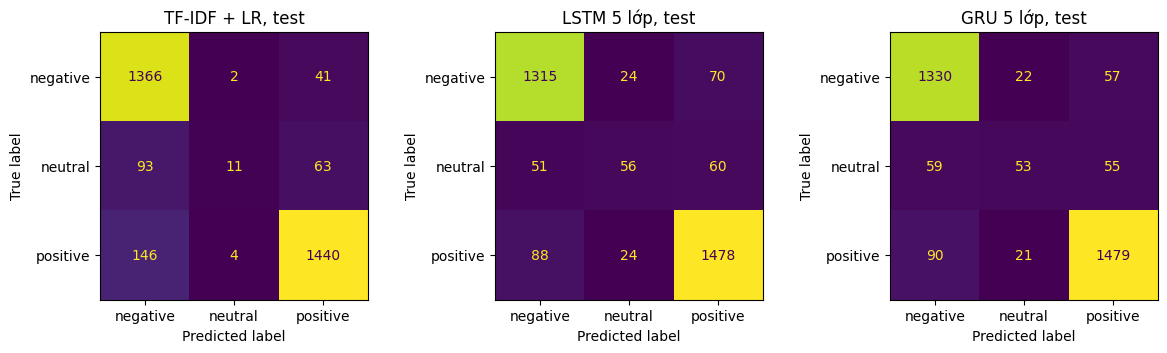

     model  accuracy  precision_macro  recall_macro  f1_macro  f1_negative  f1_neutral  f1_positive
LSTM 1 lớp    0.9024           0.7732        0.7506    0.7603       0.9195      0.4290       0.9323
LSTM 2 lớp    0.8989           0.7744        0.7354    0.7505       0.9139      0.4085       0.9292
LSTM 5 lớp    0.8999           0.7873        0.7327    0.7521       0.9186      0.4133       0.9243


BiLSTM NER test: P=0.9091 R=0.8845 entity-F1=0.8966
                     precision    recall  f1-score   support

                AGE     0.9511    0.9364    0.9437       582
               DATE     0.9665    0.9601    0.9633      1654
             GENDER     0.9832    0.8874    0.9329       462
                JOB     0.6330    0.3988    0.4894       173
           LOCATION     0.9138    0.9025    0.9081      4441
               NAME     0.7068    0.6824    0.6944       318
       ORGANIZATION     0.8516    0.7665    0.8068       771
         PATIENT_ID     0.9344    0.9591    0.9466      2005
SYMPTOM_AND_DISEASE     0.8288    0.7588    0.7923      1136
     TRANSPORTATION     0.8743    0.8653    0.8698       193

          micro avg     0.9091    0.8845    0.8966     11735
          macro avg     0.8644    0.8117    0.8347     11735
       weighted avg     0.9066    0.8845    0.8947     11735



In [27]:
from sklearn.metrics import precision_recall_fscore_support
from seqeval.metrics import precision_score as entity_p
from seqeval.metrics import recall_score as entity_r

def cls_metrics(name, true, pred):
    p, r, f, _ = precision_recall_fscore_support(
        true, pred, labels=[0, 1, 2], average="macro", zero_division=0)
    per = f1_score(true, pred, labels=[0, 1, 2], average=None, zero_division=0)
    return dict(model=name, accuracy=accuracy_score(true, pred),
                precision_macro=p, recall_macro=r, f1_macro=f,
                f1_negative=per[0], f1_neutral=per[1], f1_positive=per[2])

test_loader = cls_loader(cls_rows(vsfc["test"]))
test_true = [label_to_id[r["sentiment"]] for r in vsfc["test"]]
test_pred, rows = {}, []
for name, model in [("LSTM 5 lớp", lstm), ("GRU 5 lớp", gru)]:
    _, true, pred = evaluate_cls(model, test_loader)
    assert true == test_true
    test_pred[name] = pred
    rows.append(cls_metrics(name, true, pred))
    print(name)
    print(classification_report(true, pred, labels=[0, 1, 2],
                                target_names=LABELS, digits=4, zero_division=0))
test_pred["TF-IDF + LR"] = list(baseline.predict(
    [r["sentence"] for r in vsfc["test"]]))
rows.append(cls_metrics("TF-IDF + LR", test_true, test_pred["TF-IDF + LR"]))
cls_test = pd.DataFrame(rows)
cls_test.to_csv(ART / "classification_test.csv", index=False)
print(cls_test.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, name in zip(axes, ["TF-IDF + LR", "LSTM 5 lớp", "GRU 5 lớp"]):
    ConfusionMatrixDisplay.from_predictions(
        test_true, test_pred[name], labels=[0, 1, 2], display_labels=LABELS,
        ax=ax, colorbar=False)
    ax.set_title(name + ", test")
fig.tight_layout()
fig.savefig(ART / "classification_test.png", dpi=150)
plt.show()

# Bài 4*: test cho các độ sâu, chỉ để báo cáo
depth_test = []
for k in [1, 2, 5]:
    _, true, pred = evaluate_cls(depth_models[k], test_loader)
    depth_test.append(cls_metrics(f"LSTM {k} lớp", true, pred))
depth_test = pd.DataFrame(depth_test)
depth_test.to_csv(ART / "depth_test.csv", index=False)
print(depth_test.round(4).to_string(index=False))

# NER
ner_test_loader = ner_loader(ner_rows(ner["test"]))
ner_test_f1, ner_t, ner_p = evaluate_ner(tagger, ner_test_loader)
ner_test_p = entity_p(ner_t, ner_p, mode="strict", scheme=IOB2, zero_division=0)
ner_test_r = entity_r(ner_t, ner_p, mode="strict", scheme=IOB2, zero_division=0)
report = entity_report(ner_t, ner_p, mode="strict", scheme=IOB2,
                       digits=4, zero_division=0)
(ART / "ner_test.txt").write_text(report, encoding="utf-8")
print(f"BiLSTM NER test: P={ner_test_p:.4f} R={ner_test_r:.4f} "
      f"entity-F1={ner_test_f1:.4f}")
print(report)

### Bảng tổng hợp

In [28]:
tfidf_row = cls_test[cls_test.model == "TF-IDF + LR"].iloc[0]
lstm_info = run_info("LSTM 5 lớp", lstm, lstm_history)
gru_info = run_info("GRU 5 lớp", gru, gru_history)
ner_info = run_info("BiLSTM NER 5 lớp", tagger, ner_history)
summary = pd.DataFrame([
    dict(model="TF-IDF + LR", dev_F1=tfidf_dev_f1,
         test_F1=tfidf_row.f1_macro, parameters="uni+bigram, min_df=2",
         seconds_per_epoch=tfidf_fit_seconds, best_epoch="-"),
    dict(model="LSTM 5 lớp", dev_F1=lstm_info["dev_macro_F1"],
         test_F1=cls_test[cls_test.model == "LSTM 5 lớp"].f1_macro.iloc[0],
         parameters=lstm_info["parameters"],
         seconds_per_epoch=lstm_info["seconds_per_epoch"],
         best_epoch=lstm_info["best_epoch"]),
    dict(model="GRU 5 lớp", dev_F1=gru_info["dev_macro_F1"],
         test_F1=cls_test[cls_test.model == "GRU 5 lớp"].f1_macro.iloc[0],
         parameters=gru_info["parameters"],
         seconds_per_epoch=gru_info["seconds_per_epoch"],
         best_epoch=gru_info["best_epoch"]),
    dict(model="BiLSTM NER 5 lớp (entity-F1)", dev_F1=ner_info["dev_macro_F1"],
         test_F1=ner_test_f1, parameters=ner_info["parameters"],
         seconds_per_epoch=ner_info["seconds_per_epoch"],
         best_epoch=ner_info["best_epoch"]),
])
summary.to_csv(ART / "summary.csv", index=False)
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("F1 của ba dòng phân loại chỉ so sánh với nhau, không so với NER.")

                       model  dev_F1  test_F1           parameters  seconds_per_epoch best_epoch
                 TF-IDF + LR  0.6894   0.6483 uni+bigram, min_df=2             0.3854          -
                  LSTM 5 lớp  0.8100   0.7521              3138007            35.3022          6
                   GRU 5 lớp  0.8049   0.7513              2468823            31.0922          7
BiLSTM NER 5 lớp (entity-F1)  0.9074   0.8966              8305297            79.3653         10
F1 của ba dòng phân loại chỉ so sánh với nhau, không so với NER.


### Kết luận

| Mô hình | Dev F1 tốt nhất | Test F1 | Tham số | Giây/epoch |
|---|---|---|---|---|
| TF-IDF + LR | 0.6894 | 0.6483 | uni+bigram, min_df=2 | 0.4 (thời gian fit) |
| LSTM 5 lớp | 0.8100 (epoch 6) | 0.7521 | 3,138,007 | 35.3 |
| GRU 5 lớp | 0.8049 (epoch 7) | 0.7513 | 2,468,823 | 31.1 |
| BiLSTM NER 5 lớp | 0.9074 (epoch 10) | 0.8966 | 8,305,297 | 79.4 |

F1 của ba dòng phân loại là macro-F1, dòng NER là entity-F1 theo seqeval strict IOB2, nên không so sánh NER với ba dòng trên.

Phân loại:
- LSTM và GRU hơn TF-IDF khoảng 0.10 macro-F1 trên test. Phần lớn đến từ lớp neutral: F1 neutral là 0.41 (LSTM) và 0.40 (GRU) so với 0.12 của TF-IDF. TF-IDF có precision macro cao hơn (0.81) nhưng recall macro thấp (0.65) vì gần như không bắt được neutral.
- LSTM và GRU gần như bằng nhau (0.7521 và 0.7513), GRU có accuracy cao hơn một chút (0.904 so với 0.900). Chỉ chạy một seed nên chênh lệch này không đủ để nói mô hình nào tốt hơn. GRU rẻ hơn rõ ràng: ít hơn 21% tham số và nhanh hơn khoảng 12% mỗi epoch.
- LSTM đạt dev F1 cao nhất ở epoch 6 rồi giảm trong khi train loss vẫn giảm (từ 0.42 xuống 0.08), tức bắt đầu overfit. GRU thì dev F1 dao động quanh 0.78–0.80 từ epoch 3 và không giảm rõ rệt. Dev F1 cao hơn test khoảng 0.06. Một phần vì epoch được chọn là epoch có dev F1 cao nhất trong 10 epoch, và lớp neutral chỉ có 73 câu dev nên điểm dao động mạnh giữa các epoch.

NER:
- Entity-F1 test là 0.8966 (precision 0.909, recall 0.885), thấp hơn dev 0.9074 khoảng 0.01. Epoch tốt nhất là epoch 10, cũng là epoch cuối nên mô hình có thể còn cải thiện nếu cho chạy lâu hơn, nhưng đề giới hạn 10 epoch.
- Các loại ít mẫu như JOB (F1 test 0.49) và NAME (0.69) kém hơn hẳn các loại như DATE (0.96) hay PATIENT_ID (0.95).

Kiểm tra: dựng lại từ điển và nạp lại ba checkpoint bằng một script riêng, tính lại F1 dev/test cho kết quả trùng với notebook. Từ điển chỉ xây từ train, không có câu nào của UIT-VSFC xuất hiện ở hai tập khác nhau. PhoNER có 6 câu dev và 9 câu test trùng văn bản với train (trên 2000 và 3000 câu), ảnh hưởng không đáng kể nhưng vẫn ghi lại.

## Phần C. Bài tập về nhà


### Bài 1. LSTM 5 lớp cho phân loại cảm xúc

**Yêu cầu:** Xây LSTM num_layers=5, hidden_size=256 cho sentiment UIT-VSFC; tối ưu bằng Adam. Dùng packing, chọn epoch theo macro-F1 dev và đánh giá checkpoint đã chọn trên test. Chạy baseline TF-IDF với cùng chia tập để có mốc đối chiếu.

**Dữ liệu:** Toàn bộ UIT-VSFC: 11.426 train, 1.583 dev, 3.166 test. Chỉ dùng sentence làm đầu vào và sentiment làm nhãn; không dùng topic làm đặc trưng.

**Định dạng kết quả:** Bảng accuracy, precision-macro, recall-macro, F1-macro trên test; F1 từng lớp; confusion matrix; đường loss/F1; số tham số và thời gian/epoch. Phân tích ít nhất 3 trường hợp dự đoán sai trên dev.

**Gợi ý:** Giữ layers=5 và hidden=256. Dùng lại TextClassifier và fit_cls; không thêm Softmax trước CrossEntropyLoss.

### Bài 2. GRU 5 lớp và so sánh với LSTM

**Yêu cầu:** Xây GRU num_layers=5, hidden_size=256 trên cùng nhiệm vụ sentiment; dùng Adam. Giữ cấu hình và quy trình đánh giá của Bài 1. Lập bảng so sánh hai mô hình và baseline, giải thích chất lượng cùng chi phí huấn luyện.

**Dữ liệu:** Dùng đúng các tệp train/dev/test, từ điển, cách tách token và ánh xạ sentiment của Bài 1.

**Định dạng kết quả:** Cùng các độ đo của Bài 1, thêm bảng LSTM/GRU với F1-macro, số tham số, thời gian/epoch và epoch tốt nhất trên dev. Không giả định GRU phải thắng hoặc LSTM phải thắng.

**Gợi ý:** TextClassifier(kind='GRU') dùng h_n trực tiếp. Khởi tạo lại seed và mô hình, không tái sử dụng trạng thái optimizer của Bài 1.

### Bài 3. Encoder BiLSTM 5 lớp cho NER

**Yêu cầu:** Xây encoder gồm 5 lớp BiLSTM, hidden_size=256 cho mỗi chiều, nối Linear(512, 21) để gán nhãn BIO. Dùng packing và CrossEntropyLoss(ignore_index=-100). Chọn checkpoint theo entity-F1 dev và chấm test bằng seqeval strict IOB2.

**Dữ liệu:** Toàn bộ PhoNER_COVID19 bản syllable: 5.027 train, 2.000 dev, 3.000 test. Giữ nguyên words/tags; không tách từ lại và không đổi bộ chia tập.

**Định dạng kết quả:** Precision, recall, micro-F1 mức thực thể trên test; F1 từng loại thực thể; số tham số, thời gian/epoch, epoch tốt nhất. Phân tích ít nhất 3 kiểu lỗi trên dev; dùng ví dụ tự tạo khi minh họa trong repo công khai.

**Gợi ý:** Cắt predicted và labels theo length trước khi đổi id sang nhãn chuỗi. Không tính PAD vào F1 và không dùng token accuracy làm kết quả NER chính.

### Bài 4*. Ảnh hưởng của độ sâu hoặc CRF

**Yêu cầu:** Chọn một hướng: (a) so sánh num_layers={1,2,5} của LSTM hoặc GRU ở hidden_size=256, giữ các yếu tố còn lại; (b) bổ sung CRF sau BiLSTM và đối chiếu với Bài 3. Giữ đúng chia tập, quy trình chọn checkpoint và độ đo của bài tương ứng.

**Dữ liệu:** Dữ liệu và tiền xử lý của bài được chọn; không bổ sung dữ liệu ngoài vào phép so sánh chính.

**Định dạng kết quả:** Bảng kết quả, số tham số, thời gian/epoch và giải thích dựa trên số đo. Phân biệt thay đổi kiến trúc với thay đổi số tham số; không suy rộng từ một seed thành kết luận tuyệt đối.

Cấu hình chung cho ba bài bắt buộc: embedding=300, hidden=256, layers=5, dropout=0.3, batch=32, Adam lr=1e-3, clip_grad_norm_=1.0, seed=42, tối đa 10 epoch; giữ checkpoint có F1 dev cao nhất. Embedding được học từ đầu, không thay kiến trúc yêu cầu bằng mô hình pretrained. 